# Contexto, KPIs actuales y árbol de valor

**Responsable:** Marcos de Andrés · **Entrega 1** · Requiere `uv run novaretail all` antes de ejecutar.

Este notebook solo llama a las funciones de `src/novaretail/kpis.py` y dibuja. Produce las cifras y figuras de los apartados 1 y 2 de la memoria:

1. El *dashboard actual*: KPIs sobre datos en bruto, tal como los ve la dirección.
2. Los mismos KPIs sobre datos validados, por canal, región y mes.
3. Margen por canal y nivel de descuento.
4. Árbol de valor cuantificado (M1).
5. Diagrama del proceso de principio a fin.

In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

from novaretail import ingest, kpis
from novaretail.config import CLEAN, FIGURES, META

FIGURES.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = '{:,.3f}'.format
pd.options.display.width = 200
pd.options.display.max_columns = 20

# Estilo común: tinta oscura, rejilla recesiva y un color fijo por canal (mismo orden en todas las figuras)
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e6e5e1'
CH_COLOR = {'tienda': '#2a78d6', 'web': '#eb6834', 'app': '#1baf7a', 'marketplace': '#6250d6'}
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'axes.labelcolor': INK2, 'xtick.color': INK2,
                     'ytick.color': INK2, 'text.color': INK, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True})

def es(x, d=0):
    """Formato español: 1.234,5"""
    return f'{x:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

stores = ingest.load_stores()
orders_raw = ingest.load_orders()
orders = pd.read_parquet(CLEAN / 'orders.parquet')
sales = pd.read_parquet(CLEAN / 'sales.parquet')
products = pd.read_parquet(CLEAN / 'products.parquet')
inventory = pd.read_parquet(CLEAN / 'inventory_weekly.parquet')
stores_clean = pd.read_parquet(CLEAN / 'stores.parquet')

## 1. KPIs tal como los ve hoy la dirección (datos en bruto)

In [2]:
dash = kpis.current_dashboard(orders_raw, stores)
dash['total']

,valor
pedidos,"78,651.000"
filas,"80,224.000"
ingresos_eur,"10,274,866.030"
ingresos_netos_eur,"9,113,455.090"
margen_contribucion_eur,"2,785,529.660"
margen_pct,0.271
ticket_medio_eur,128.077
tasa_devolucion,0.094
tasa_cancelacion,0.015
entrega_a_tiempo,0.910


In [3]:
# El dashboard actual por canal: el mismo canal aparece con varias etiquetas
print('Etiquetas de canal distintas en el dashboard actual:', dash['canal'].shape[0])
dash['canal'][['pedidos', 'ingresos_eur', 'margen_pct', 'entrega_a_tiempo']]

Etiquetas de canal distintas en el dashboard actual: 14


,pedidos,ingresos_eur,margen_pct,entrega_a_tiempo
channel,,,,
web,153.000,"18,689.140",0.193,0.881
APP,167.000,"42,407.700",0.599,0.854
App,176.000,"23,236.710",0.212,0.818
Marketplace,79.000,"10,673.970",-0.041,0.925
TIENDA,237.000,"29,571.230",0.266,1.000
Tienda,212.000,"29,465.550",0.431,1.000
WEB,129.000,"17,763.060",0.176,0.845
Web,119.000,"18,172.360",0.340,0.857
app,"17,083.000","2,386,125.160",0.279,0.822


In [4]:
# Por región: las tiendas con espacios o nulos no se pueden asignar a ninguna región
dash['region'][['pedidos', 'ingresos_eur', 'margen_pct', 'entrega_a_tiempo']]

,pedidos,ingresos_eur,margen_pct,entrega_a_tiempo
region,,,,
(sin región),"1,177.000","140,838.630",0.214,0.917
Centro,"24,036.000","3,210,217.980",0.279,0.941
Este,"21,706.000","2,823,013.280",0.282,0.874
Norte,"13,910.000","1,815,260.440",0.264,0.879
Sur,"17,822.000","2,285,535.700",0.256,0.935


In [5]:
# Por mes: aparecen meses posteriores al fin de los datos (pedidos con fecha futura)
mes = dash['mes']
print('Meses en el dashboard actual:', mes.index.min(), '->', mes.index.max())
print('Pedidos en meses posteriores a oct-2026:', int(mes[mes.index > '2026-10']['pedidos'].sum()))
mes.tail(6)[['pedidos', 'ingresos_eur', 'entrega_a_tiempo']]

Meses en el dashboard actual: 2025-01 -> 2027-10
Pedidos en meses posteriores a oct-2026: 88


,pedidos,ingresos_eur,entrega_a_tiempo
month,,,
2027-05,6.000,644.250,1.000
2027-06,9.000,"1,395.780",0.889
2027-07,9.000,"1,032.260",1.000
2027-08,1.000,450.820,1.000
2027-09,10.000,803.590,0.900
2027-10,3.000,290.280,1.000


## 2. KPIs validados por canal, región y mes
Son los datos de `data/clean` (contratos de la Persona 2). La comparación detallada ingenuo frente a validado (M2) es del apartado 3.3.

In [6]:
val_total = kpis.order_kpis(orders)
val_canal = kpis.kpis_by(orders, 'channel', stores_clean)
val_region = kpis.kpis_by(orders, 'region', stores_clean)
val_mes = kpis.kpis_by(orders, 'month', stores_clean)
val_canal

,pedidos,filas,ingresos_eur,ingresos_netos_eur,margen_contribucion_eur,margen_pct,ticket_medio_eur,tasa_devolucion,tasa_cancelacion,entrega_a_tiempo
channel,,,,,,,,,,
app,"16,660.000","16,660.000","2,041,050.530","1,735,710.730","414,635.950",0.203,122.512,0.121,0.026,0.821
marketplace,"7,162.000","7,162.000","825,087.090","681,987.370","17,434.730",0.021,115.203,0.143,0.028,0.944
tienda,"31,756.000","31,756.000","3,480,447.350","3,264,458.450","971,950.470",0.279,109.600,0.057,0.000,1.000
web,"19,367.000","19,367.000","2,419,769.620","2,091,861.530","495,659.830",0.205,124.943,0.114,0.024,0.820


In [7]:
val_region

,pedidos,filas,ingresos_eur,ingresos_netos_eur,margen_contribucion_eur,margen_pct,ticket_medio_eur,tasa_devolucion,tasa_cancelacion,entrega_a_tiempo
region,,,,,,,,,,
Centro,"23,195.000","23,195.000","2,716,620.050","2,427,297.620","588,110.810",0.216,117.121,0.090,0.014,0.941
Este,"20,986.000","20,986.000","2,441,357.700","2,151,018.330","538,053.120",0.220,116.333,0.096,0.014,0.873
Norte,"13,447.000","13,447.000","1,575,270.550","1,397,486.020","334,395.370",0.212,117.147,0.093,0.016,0.879
Sur,"17,317.000","17,317.000","2,033,106.290","1,798,216.110","439,121.680",0.216,117.405,0.095,0.015,0.935


In [8]:
# Puntualidad solo en pedidos online (en tienda la entrega es inmediata y siempre está 'a tiempo')
o = kpis.prepare_orders(orders, stores_clean)
online = o[(o['channel'] != 'tienda') & o['delivered_ts'].notna()].copy()
online['tarde'] = online['delivered_ts'] > online['promised_ts']
print(f"Pedidos online entregados tarde: {online['tarde'].mean():.1%}")
print(online.groupby('region')['tarde'].mean().round(3).to_dict())
pico = online['month'].isin(['2025-11', '2025-12'])
print(f"Nov-dic 2025: {online[pico]['tarde'].mean():.1%} · resto: {online[~pico]['tarde'].mean():.1%}")

Pedidos online entregados tarde: 15.9%
{'Centro': 0.104, 'Este': 0.224, 'Norte': 0.211, 'Sur': 0.114}
Nov-dic 2025: 20.3% · resto: 15.2%


## 3. Margen por canal y nivel de descuento (figura de la memoria)

% de líneas con descuento >= 30 %: {'app': 0.106, 'marketplace': 0.22, 'tienda': 0.067, 'web': 0.1}


channel,tienda,web,app,marketplace
discount_pct,,,,
0,0.325,0.296,0.296,0.300
5,0.288,0.268,0.256,0.258
10,0.252,0.212,0.216,0.222
15,0.208,0.167,0.171,0.170
20,0.158,0.111,0.121,0.115
30,0.039,-0.016,0.006,-0.018
40,-0.136,-0.167,-0.168,-0.168
50,-0.338,-0.398,-0.392,-0.418


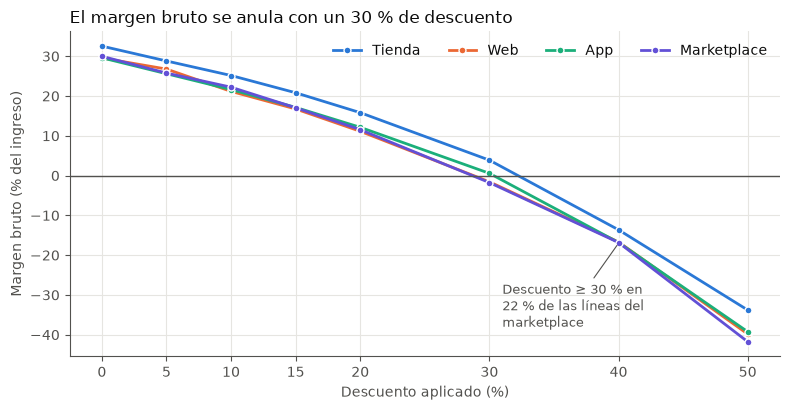

In [9]:
md = kpis.margin_by_discount(sales, products)
piv = md.pivot(index='discount_pct', columns='channel', values='margen_bruto_pct')[list(CH_COLOR)]
share = sales.groupby('channel')['discount_pct'].apply(lambda s: (s >= 30).mean())
print('% de líneas con descuento >= 30 %:', share.round(3).to_dict())

fig, ax = plt.subplots(figsize=(8, 4.2))
for ch, col in CH_COLOR.items():
    ax.plot(piv.index, piv[ch] * 100, marker='o', ms=5, lw=2, color=col, label=ch.capitalize(),
            markeredgecolor='white', markeredgewidth=1)
ax.axhline(0, color=INK2, lw=1)
ax.set_xlabel('Descuento aplicado (%)')
ax.set_ylabel('Margen bruto (% del ingreso)')
ax.set_xticks(piv.index)
ax.set_title('El margen bruto se anula con un 30 % de descuento', loc='left', fontsize=12, color=INK)
ax.legend(frameon=False, ncol=4, loc='upper right')
ax.annotate('Descuento ≥ 30 % en\n22 % de las líneas del\nmarketplace', xy=(40, -17), xytext=(31, -38),
            fontsize=9, color=INK2, arrowprops=dict(arrowstyle='-', color=INK2, lw=0.8))
fig.tight_layout()
fig.savefig(FIGURES / 'p1_margen_descuento_canal.png', dpi=200, bbox_inches='tight')
piv.round(3)

## 4. Puntualidad online por región y mes (figura de la memoria)

region,Centro,Este,Norte,Sur
month,,,,
2026-05,8.700,24.500,22.900,13.600
2026-06,11.300,19.600,22.000,11.200
2026-07,11.100,25.300,19.300,12.300
2026-08,9.900,21.000,21.100,13.000
2026-09,11.400,20.900,19.500,10.500
2026-10,9.200,19.500,18.800,9.400


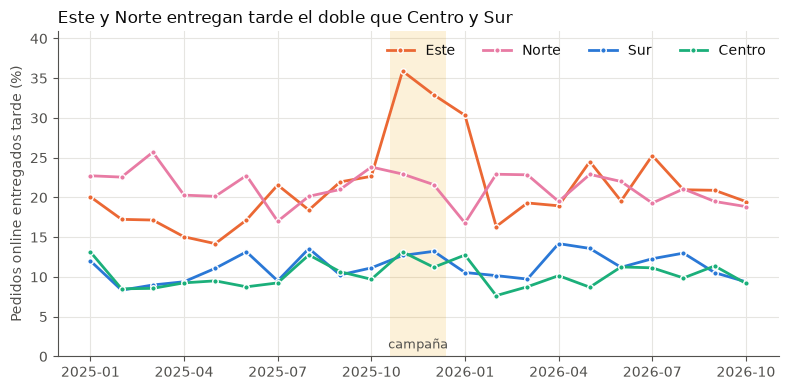

In [10]:
tarde_mes = online.groupby(['month', 'region'])['tarde'].mean().unstack() * 100
REG_COLOR = {'Este': '#eb6834', 'Norte': '#e87ba4', 'Sur': '#2a78d6', 'Centro': '#1baf7a'}
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(tarde_mes))
for reg, col in REG_COLOR.items():
    ax.plot(x, tarde_mes[reg], lw=2, color=col, label=reg, marker='o', ms=4, markeredgecolor='white')
ax.set_xticks(list(x)[::3]); ax.set_xticklabels(list(tarde_mes.index)[::3], rotation=0)
ax.axvspan(10 - .4, 11 + .4, color='#eda100', alpha=.15, lw=0)
ax.text(10.5, 1, 'campaña', ha='center', fontsize=9, color=INK2)
ax.set_ylabel('Pedidos online entregados tarde (%)')
ax.set_title('Este y Norte entregan tarde el doble que Centro y Sur', loc='left', fontsize=12, color=INK)
ax.legend(frameon=False, ncol=4, loc='upper right')
ax.set_ylim(0, tarde_mes.values.max() + 5)
fig.tight_layout()
fig.savefig(FIGURES / 'p1_puntualidad_region_mes.png', dpi=200, bbox_inches='tight')
tarde_mes.round(1).tail(6)

## 5. Árbol de valor

Beneficio anual de decidir con datos fiables, en euros, sobre los últimos 12 meses (nov-2025 a oct-2026, que incluye la campaña).
Los supuestos están en `kpis.ASSUMPTIONS`, con escenarios bajo/base/alto.

**Aviso sobre los tickets:** la prioridad de cada ticket sale de `data/_meta/tickets_labels.csv`. Se usa solo para dimensionar el problema; cuando la Persona 4 tenga `classify_ticket()`, hay que sustituirla por la prioridad predicha.

In [11]:
labels = pd.read_csv(META / 'tickets_labels.csv')
tickets = ingest.load_tickets().merge(labels, on='ticket_id')
tree = kpis.value_tree(orders, sales, products, inventory, tickets, stores_clean)
ref = tree.attrs['margen_anual_referencia_eur']
pd.options.display.float_format = '{:,.0f}'.format
tree[['rama', 'nivel', 'responsable', 'exposicion_eur', 'bajo', 'base', 'alto', 'confianza']]

,rama,nivel,responsable,exposicion_eur,bajo,base,alto,confianza
0,1. Descuentos que destruyen margen,Estratégico,Comercial / Finanzas,"59,337","14,834","29,668","44,503",Alta (dato validado)
1,2. Roturas de stock,Táctico,Operaciones / Compras,"24,520","7,356","12,260","17,164",Media (estimación de demanda)
2,3. Pedidos cancelados,Operativo,Operaciones,"15,438","1,544","3,859","6,175",Media (causa de cancelación desconocida)
3,4. Tickets urgentes sin priorizar,Operativo,Soporte,"5,672","1,134","1,702","2,269",Baja (costes unitarios supuestos)
4,5. Coste de gestionar retrasos,Operativo,Operaciones / Soporte,"6,116","1,835","3,058","4,282",Media (coste de gestión supuesto)
5,TOTAL valor anual,,,"111,083","26,703","50,548","74,392",


In [12]:
tot = tree.iloc[-1]
print(f"Margen de contribución de referencia (12 meses): {es(ref)} EUR")
print(f"Valor anual: base {es(tot['base'])} EUR ({tot['base'] / ref:.1%} del margen) · rango {es(tot['bajo'])} - {es(tot['alto'])} EUR")
print(f"Exposición total (antes de supuestos de recuperación): {es(tot['exposicion_eur'])} EUR")
tree[['rama', 'dato', 'supuesto']].iloc[:-1].to_dict('records')

Margen de contribución de referencia (12 meses): 1.134.720 EUR
Valor anual: base 50.548 EUR (4.5% del margen) · rango 26.703 - 74.392 EUR
Exposición total (antes de supuestos de recuperación): 111.083 EUR


[{'rama': '1. Descuentos que destruyen margen',
  'dato': '4.393 pedidos entregados con margen < 0 (de ellos 1.672 en marketplace)',
  'supuesto': 'Se evita o reprecia la parte indicada de esa pérdida (tope de descuento del 20-30 %)'},
 {'rama': '2. Roturas de stock',
  'dato': '9.846 semanas tienda-producto sin stock',
  'supuesto': 'Reposición anticipada recupera la parte indicada del margen perdido (estimación simple; la Persona 3 calcula el margen en riesgo)'},
 {'rama': '3. Pedidos cancelados',
  'dato': '662 cancelaciones; margen que habrían dado 12.639 EUR + coste ya incurrido 2.798 EUR',
  'supuesto': 'Intervenir los pedidos en riesgo evita la parte indicada de las cancelaciones'},
 {'rama': '4. Tickets urgentes sin priorizar',
  'dato': '413 tickets de prioridad alta en 12 meses (2.252 en total)',
  'supuesto': 'Sin prioridad, la cola es FIFO; la clasificación reduce los incidentes en los puntos de % indicados'},
 {'rama': '5. Coste de gestionar retrasos',
  'dato': '941 ticke

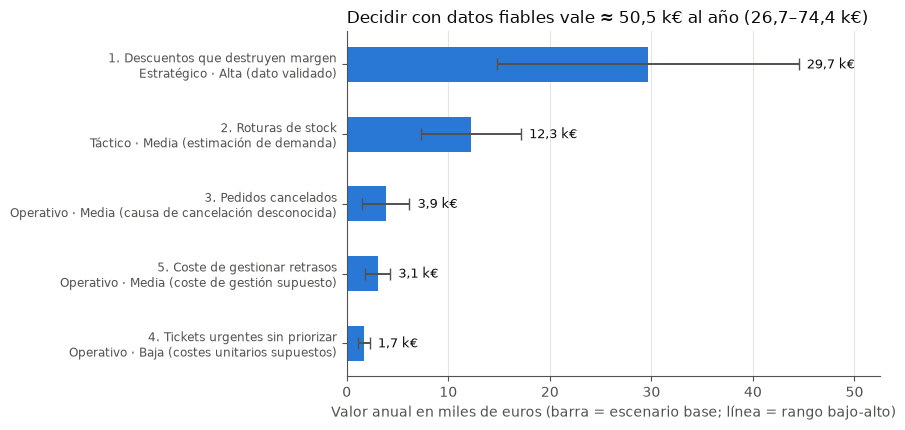

In [13]:
br = tree.iloc[:-1].sort_values('base')
fig, ax = plt.subplots(figsize=(9, 4.4))
y = range(len(br))
ax.barh(list(y), br['base'] / 1000, color='#2a78d6', height=0.5)
ax.errorbar(br['base'] / 1000, list(y), xerr=[(br['base'] - br['bajo']) / 1000, (br['alto'] - br['base']) / 1000],
            fmt='none', ecolor=INK2, elinewidth=1.4, capsize=4)
ax.set_yticks(list(y)); ax.set_yticklabels([f"{r}\n{n} · {c}" for r, n, c in zip(br['rama'], br['nivel'], br['confianza'])], fontsize=8.5)
for yi, (b, hi) in enumerate(zip(br['base'], br['alto'])):
    ax.text(hi / 1000 + 0.8, yi, f"{es(b / 1000, 1)} k€", va='center', fontsize=9, color=INK)
ax.set_xlabel('Valor anual en miles de euros (barra = escenario base; línea = rango bajo-alto)')
ax.set_xlim(0, br['alto'].max() / 1000 * 1.18)
ax.grid(axis='y', visible=False)
ax.set_title(f"Decidir con datos fiables vale ≈ {es(tot['base'] / 1000, 1)} k€ al año ({es(tot['bajo'] / 1000, 1)}–{es(tot['alto'] / 1000, 1)} k€)",
             loc='left', fontsize=12, color=INK)
fig.tight_layout()
fig.savefig(FIGURES / 'p1_arbol_valor.png', dpi=200, bbox_inches='tight')

In [14]:
# Sensibilidad: ¿cuánto cambia el total si todos los porcentajes de recuperación suben o bajan?
import copy
rows = []
for k in ['bajo', 'base', 'alto']:
    a = copy.deepcopy(kpis.ASSUMPTIONS)
    t = kpis.value_tree(orders, sales, products, inventory, tickets, stores_clean, assumptions=a)
    rows.append((k, t.iloc[-1][k]))
print({k: round(v) for k, v in rows})

# Sensibilidad al coste unitario supuesto de los tickets (rama más débil): x0,5 y x2
for f in (0.5, 2):
    a = copy.deepcopy(kpis.ASSUMPTIONS)
    a['coste_incidente_eur'] = {k: v * f for k, v in a['coste_incidente_eur'].items()}
    a['coste_gestion_ticket_eur'] *= f
    t = kpis.value_tree(orders, sales, products, inventory, tickets, stores_clean, assumptions=a)
    print(f'costes de tickets x{f}: total base {t.iloc[-1]["base"]:,.0f} EUR')

{'bajo': 26703, 'base': 50548, 'alto': 74392}
costes de tickets x0.5: total base 48,168 EUR


costes de tickets x2: total base 55,307 EUR


In [15]:
# Dónde se pierde el margen por roturas (insumo provisional; el margen en riesgo prospectivo es de la Persona 3)
lost = kpis.stockout_lost_margin(inventory, sales, products, stores_clean, since=tree.attrs['desde'])
print(lost.groupby('region')['margen_perdido_eur'].sum().round(0).to_dict())
print(lost.groupby('category')['margen_perdido_eur'].sum().sort_values(ascending=False).round(0).head(3).to_dict())
lost.head(5)

{'Centro': 5698.0, 'Este': 8031.0, 'Norte': 3521.0, 'Sur': 7270.0}
{'Moda': 10710.0, 'Electronica': 4996.0, 'Belleza': 2336.0}


,store_id,product_id,semanas_sin_stock,demanda_semanal,margen_unitario_eur,margen_perdido_eur,region,category
0,S021,P0381,3,6,15,285,Este,Moda
1,S022,P0381,4,4,15,214,Este,Moda
2,S011,P0381,3,4,15,195,Sur,Moda
3,S021,P0124,3,2,33,165,Este,Moda
4,S030,P0381,3,3,15,149,Este,Moda


## 6. Diagrama del proceso de principio a fin

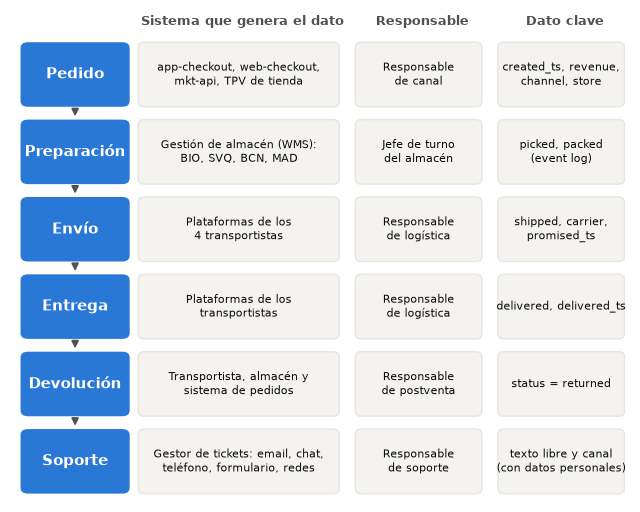

In [16]:
etapas = [
    ('Pedido', 'app-checkout, web-checkout,\nmkt-api, TPV de tienda', 'Responsable\nde canal', 'created_ts, revenue,\nchannel, store'),
    ('Preparación', 'Gestión de almacén (WMS):\nBIO, SVQ, BCN, MAD', 'Jefe de turno\ndel almacén', 'picked, packed\n(event log)'),
    ('Envío', 'Plataformas de los\n4 transportistas', 'Responsable\nde logística', 'shipped, carrier,\npromised_ts'),
    ('Entrega', 'Plataformas de los\ntransportistas', 'Responsable\nde logística', 'delivered, delivered_ts'),
    ('Devolución', 'Transportista, almacén y\nsistema de pedidos', 'Responsable\nde postventa', 'status = returned'),
    ('Soporte', 'Gestor de tickets: email, chat,\nteléfono, formulario, redes', 'Responsable\nde soporte', 'texto libre y canal\n(con datos personales)'),
]
cols = [('Proceso', 0.02, 0.17), ('Sistema que genera el dato', 0.21, 0.33), ('Responsable', 0.56, 0.21), ('Dato clave', 0.79, 0.21)]
fig, ax = plt.subplots(figsize=(8, 6.4)); ax.axis('off'); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
rh, gap, top = 0.125, 0.032, 0.93
for nom, x0, w in cols[1:]:
    ax.text(x0 + w / 2, 0.975, nom, ha='center', va='center', fontsize=9, fontweight='bold', color=INK2)
for i, (nom, sis, resp, dato) in enumerate(etapas):
    y = top - (i + 1) * rh - i * gap
    ax.add_patch(FancyBboxPatch((0.02, y), 0.17, rh, boxstyle='round,pad=0.003,rounding_size=0.012', fc='#2a78d6', ec='none'))
    ax.text(0.105, y + rh / 2, nom, ha='center', va='center', color='white', fontsize=10.5, fontweight='bold')
    if i < len(etapas) - 1:
        ax.annotate('', xy=(0.105, y - gap + 0.004), xytext=(0.105, y - 0.004), arrowprops=dict(arrowstyle='-|>', color=INK2, lw=1.4))
    for txt, (_, x0, w) in zip([sis, resp, dato], cols[1:]):
        ax.add_patch(FancyBboxPatch((x0, y), w - 0.012, rh, boxstyle='round,pad=0.003,rounding_size=0.01', fc='#f4f3f0', ec=GRID))
        ax.text(x0 + (w - 0.012) / 2, y + rh / 2, txt, ha='center', va='center', fontsize=8.2, color=INK)
fig.savefig(FIGURES / 'p1_proceso_extremo_a_extremo.png', dpi=200, bbox_inches='tight')

## Conclusiones para la memoria

1. **Margen desigual por canal y descuento.** El marketplace aporta el 9,4 % de los ingresos validados y solo el 0,9 % del margen (2,1 % de margen frente al 27,9 % de tienda). Un descuento del 30 % anula el margen bruto, y el 22 % de las líneas del marketplace lo supera. *Decisión:* tope de descuentos y repreciado del marketplace. *Responsable:* Comercial y Finanzas.
2. **Retrasos concentrados.** El 15,9 % de los pedidos online llega tarde: 22,4 % en Este y 21,1 % en Norte frente al 10,4 % de Centro y el 11,4 % de Sur, y sube al 20,3 % en nov-dic. *Decisión:* capacidad por almacén y transportista (apartado 3.5, Persona 3). *Responsable:* Operaciones.
3. **El dashboard actual no es fiable.** Muestra 14 etiquetas de canal en lugar de 4, pedidos asignados a meses de 2027 y un margen del 27,1 % que baja al 21,7 % con los datos validados.
4. **El valor de decidir bien es modesto pero claro.** ≈ 50 k€ al año en el escenario base (27–74 k€), el 4,5 % del margen anual. Los descuentos y las roturas de stock suman el 83 % del total.
5. **Límite:** en estos datos, la entrega tardía no eleva la tasa de devolución ni reduce la recompra a 90 días dentro de cada canal, así que no se le asigna valor por ese camino.